In [1]:
%pip install matplotlib numpy scikit-learn opencv-python-headless kagglehub imutils mlflow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, json, numpy as np, tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight
tfl = tf.keras.layers


2026-10-23 16:49:52.947132: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792774192.959106  227908 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792774192.962702  227908 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792774192.972785  227908 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792774192.972795  227908 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792774192.972796  227908 computation_placer.cc:177] computation placer alr

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("abd0id/mri-scans")

print("Path to dataset files:", path)

Path to dataset files: /root/.cache/kagglehub/datasets/abd0id/mri-scans/versions/1


In [4]:
import os

image_paths = []


In [5]:
directory = os.path.join(path, "processed")
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)
IMG_SIZE, BATCH_SIZE, SEED = (224, 224), 32, 42

class_names = sorted(d for d in os.listdir(directory) if os.path.isdir(f"{directory}/{d}"))
NUM_CLASSES = len(class_names)
paths, labels = [], []
for i, c in enumerate(class_names):
    for f in os.listdir(f"{directory}/{c}"):
        paths.append(f"{directory}/{c}/{f}"); labels.append(i)
paths, labels = np.array(paths), np.array(labels)

p_tr, p_tmp, y_tr, y_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_val, p_te, y_val, y_te = train_test_split(p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(len(p_tr), len(p_val), len(p_te), class_names)

def load(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)          # raw 0-255 preprocess_input is inside the model
    return img, tf.one_hot(label, NUM_CLASSES)

def make_ds(p, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if training:
        ds = ds.shuffle(len(p), seed=SEED)
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE)
    return ds.prefetch(tf.data.AUTOTUNE) if training else ds.cache().prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(p_tr, y_tr, True), make_ds(p_val, y_val), make_ds(p_te, y_te)
cw = dict(enumerate(compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_tr)))

4708 1009 1009 ['glioma', 'meningioma', 'notumor', 'pituitary']


I0000 00:00:1792774196.998311  227908 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22328 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3090, pci bus id: 0000:a2:00.0, compute capability: 8.6


In [6]:
data_augmentation = tf.keras.Sequential([
    tfl.RandomRotation(0.03), tfl.RandomZoom(0.1), tfl.RandomTranslation(0.05, 0.05)])  # training only
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

def build_model():
    base = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,),
                                             include_top=False, weights="imagenet")
    base.trainable = False
    inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
    x = data_augmentation(inputs)
    x = preprocess_input(x)
    x = base(x, training=False)            # keeps BatchNorm in inference mode also during finetuning
    x = tfl.GlobalAveragePooling2D()(x)
    x = tfl.Dropout(0.2)(x)
    outputs = tfl.Dense(NUM_CLASSES, activation="softmax")(x)
    return tf.keras.Model(inputs, outputs), base

model, base_model = build_model()
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

def callbacks(name):
    return [
        tf.keras.callbacks.ModelCheckpoint(f"{OUT}/{name}_best.keras", monitor="val_loss", save_best_only=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        tf.keras.callbacks.BackupAndRestore(f"{OUT}/backup_{name}"),
    ]

h1 = model.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=cw, callbacks=callbacks("transfer"))

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/15


I0000 00:00:1792774204.585190  228699 cuda_dnn.cc:529] Loaded cuDNN version 90300


148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 51ms/step - accuracy: 0.6305 - loss: 0.9120 - val_accuracy: 0.7483 - val_loss: 0.6234
Epoch 2/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.8308 - loss: 0.4425 - val_accuracy: 0.7869 - val_loss: 0.5408
Epoch 3/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - accuracy: 0.8626 - loss: 0.3568 - val_accuracy: 0.7681 - val_loss: 0.6034
Epoch 4/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.8757 - loss: 0.3401 - val_accuracy: 0.8127 - val_loss: 0.4892
Epoch 5/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.8858 - loss: 0.3130 - val_accuracy: 0.8583 - val_loss: 0.3843
Epoch 6/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.8995 - loss: 0.2848 - val_accuracy: 0.8434 - val_loss: 0.4160
Epoch 7/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.8982 - loss: 0.2777 - val_accuracy: 0.8176 - val_loss: 0.4894
Epoch 8/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.8949 - loss: 0.2678 - val_accuracy: 0.84

In [7]:
FINE_TUNE_AT = 100                          # MobileNetV2 has 154 layers: freeze 0-99, train 100+
base_model.trainable = True
for layer in base_model.layers[:FINE_TUNE_AT]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),   # 10x lower: gentle updates, keeps ImageNet knowledge
              loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

h2 = model.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=cw, callbacks=callbacks("finetune"))

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 1,866,564 (7.12 MB)

 Non-trainable params: 396,544 (1.51 MB)

Epoch 1/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 17s 55ms/step - accuracy: 0.8365 - loss: 0.5042 - val_accuracy: 0.8028 - val_loss: 0.6693
Epoch 2/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 49ms/step - accuracy: 0.9426 - loss: 0.1528 - val_accuracy: 0.9058 - val_loss: 0.2965
Epoch 3/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 49ms/step - accuracy: 0.9685 - loss: 0.0925 - val_accuracy: 0.9227 - val_loss: 0.2271
Epoch 4/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.9783 - loss: 0.0624 - val_accuracy: 0.8900 - val_loss: 0.3867
Epoch 5/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 49ms/step - accuracy: 0.9756 - loss: 0.0774 - val_accuracy: 0.9247 - val_loss: 0.2630
Epoch 6/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 8s 53ms/step - accuracy: 0.9861 - loss: 0.0400 - val_accuracy: 0.9346 - val_loss: 0.2250
Epoch 7/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.9927 - loss: 0.0235 - val_accuracy: 0.9376 - val_loss: 0.2321
Epoch 8/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 8s 50ms/step - accuracy: 0.9873 - loss: 0.0340 - val_acc

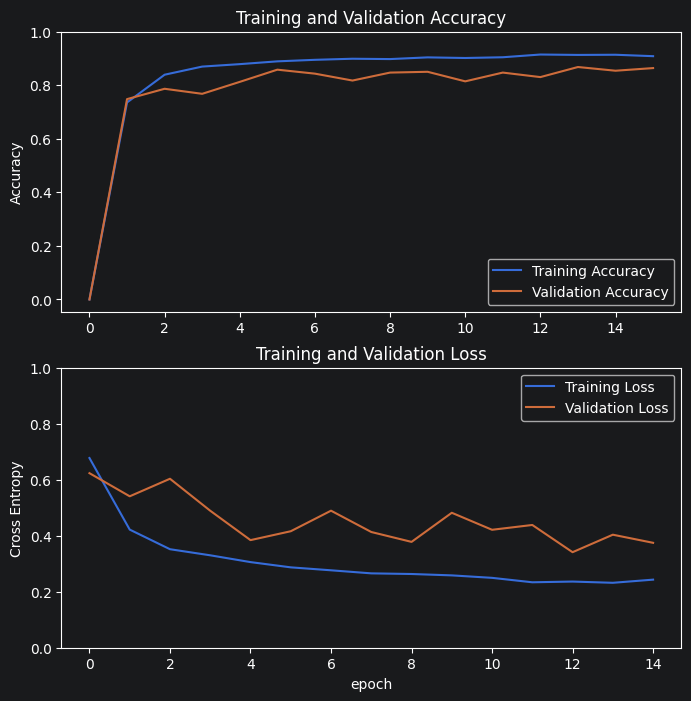

In [8]:
import matplotlib.pyplot as plt

# Changed 'history.history' to 'h1.history' to match your training variable
acc = [0.] + h1.history['accuracy']
val_acc = [0.] + h1.history['val_accuracy']

loss = h1.history['loss']
val_loss = h1.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

In [12]:
!pip install --force-reinstall "protobuf==3.20.3"

  Using cached protobuf-3.20.3-cp310-cp310-manylinux_2_12_x86_64.manylinux2010_x86_64.whl (1.1 MB)
  Attempting uninstall: protobuf
    Found existing installation: protobuf 7.36.2
    Uninstalling protobuf-7.36.2:
      Successfully uninstalled protobuf-7.36.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opentelemetry-proto 1.45.1 requires protobuf<8.0,>=5.0, but you have protobuf 3.20.3 which is incompatible.
databricks-sdk 0.156.0 requires protobuf!=5.26.*,!=5.27.*,!=5.28.*,!=5.29.0,!=5.29.1,!=5.29.2,!=5.29.3,!=5.29.4,!=6.30.0,!=6.30.1,!=6.31.0,<8.0,>=4.25.8, but you have protobuf 3.20.3 which is incompatible.


In [14]:
import mlflow
import mlflow.tensorflow

# 1. Point the VM to your local machine via the Ngrok tunnel
mlflow.set_tracking_uri("https://early-cider-dismount.ngrok-free.dev")

# 2. Set the experiment name
mlflow.set_experiment("NeuroVision_Transfer_Learning")

# 3. Enable automatic logging for Keras/TensorFlow
mlflow.tensorflow.autolog()

# 4. Start the training run
with mlflow.start_run(run_name="MobileNetV2_Fine_Tuning"):

    # Run the training
    h2 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=10,
        class_weight=cw
        # (Make sure to remove EarlyStopping from callbacks if you want it to run all 10 epochs)
    )

2026-10-23 16:56:19.816561: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-10-23 16:56:20.225744: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Epoch 1/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9951 - loss: 0.0197  

148/148 ━━━━━━━━━━━━━━━━━━━━ 24s 161ms/step - accuracy: 0.9951 - loss: 0.0198 - val_accuracy: 0.9504 - val_loss: 0.1913
Epoch 2/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - accuracy: 0.9841 - loss: 0.0446 - val_accuracy: 0.9405 - val_loss: 0.2217
Epoch 3/10
147/148 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.9866 - loss: 0.0375  

148/148 ━━━━━━━━━━━━━━━━━━━━ 15s 103ms/step - accuracy: 0.9866 - loss: 0.0376 - val_accuracy: 0.9643 - val_loss: 0.1422
Epoch 4/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 48ms/step - accuracy: 0.9883 - loss: 0.0308 - val_accuracy: 0.9524 - val_loss: 0.1935
Epoch 5/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step - accuracy: 0.9846 - loss: 0.0436 - val_accuracy: 0.9673 - val_loss: 0.1647
Epoch 6/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - accuracy: 0.9910 - loss: 0.0202 - val_accuracy: 0.9673 - val_loss: 0.1573
Epoch 7/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step - accuracy: 0.9946 - loss: 0.0153 - val_accuracy: 0.9613 - val_loss: 0.2080
Epoch 8/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.9826 - loss: 0.0551  

148/148 ━━━━━━━━━━━━━━━━━━━━ 13s 87ms/step - accuracy: 0.9826 - loss: 0.0550 - val_accuracy: 0.9722 - val_loss: 0.1034
Epoch 9/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - accuracy: 0.9857 - loss: 0.0353 - val_accuracy: 0.9504 - val_loss: 0.2209
Epoch 10/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.9883 - loss: 0.0457 - val_accuracy: 0.9762 - val_loss: 0.1267
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 698ms/step


2026/10/23 16:58:02 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run MobileNetV2_Fine_Tuning at: https://early-cider-dismount.ngrok-free.dev/#/experiments/1/runs/ff02fb80c43b48b084acf9f86f5230ba
🧪 View experiment at: https://early-cider-dismount.ngrok-free.dev/#/experiments/1


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Start a run to log our test metrics
with mlflow.start_run(run_name="Model_Evaluation"):
    print("Evaluating on test dataset...")

    # Extract actual labels from the tf.data dataset
    y_true = np.concatenate([y.numpy() for x, y in test_ds], axis=0)
    y_true_classes = np.argmax(y_true, axis=1)

    # Generate predictions
    predictions = model.predict(test_ds)
    y_pred_classes = np.argmax(predictions, axis=1)

    # 2. Calculate and log manual metrics (just like your snippet)
    from sklearn.metrics import accuracy_score
    mlflow.log_metric("test_accuracy", accuracy_score(y_true_classes, y_pred_classes))

    # 3. Create, save, and log the Classification Report
    report = classification_report(y_true_classes, y_pred_classes, target_names=class_names)
    print(report)

    report_path = "classification_report.txt"
    with open(report_path, "w") as f:
        f.write(report)
    mlflow.log_artifact(report_path) # Sends the text file to your local MLflow server

    # 4. Create, save, and log the Confusion Matrix
    cm = confusion_matrix(y_true_classes, y_pred_classes)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.title('Test Set Confusion Matrix')

    cm_path = "confusion_matrix.png"
    plt.savefig(cm_path)
    mlflow.log_artifact(cm_path) # Sends the image to your local MLflow server
    plt.show()

    # 5. Log the final model to the MLflow Registry
    # This makes it accessible for your Streamlit app later
    mlflow.tensorflow.log_model(
        model,
        artifact_path="mri_model",
        registered_model_name="NeuroVision_MRI_Classifier"
    )